# HistGradientBoosting: boosting com validação por município (Fase 3)

**Objetivo:** segundo modelo de ensemble do grupo. Enquanto a Random Forest (notebook 04)
treina árvores **independentes** e tira a média (bagging), o boosting treina árvores
**em sequência**, cada uma corrigindo os erros das anteriores. Usa-se o
`HistGradientBoostingClassifier` do scikit-learn: rápido na escala de 1,3 milhão de linhas e sem
dependência nova.

| Etapa | Aula de referência |
|---|---|
| Boosting / ensemble | Supervisionados, Aula 4 |
| Overfitting por número de iterações (curva de aprendizado) | Otimização, Aula 5 (`slide14`, `slide16`) |
| `RandomizedSearchCV` | Otimização, Aula 2 |
| Limiar, teste único, SHAP | Otimização, Aulas 4 e 3 |

O fluxo é o mesmo do notebook 04, de propósito: assim a comparação entre os modelos é justa.
Os `TODO` dependem dos números da sua execução.

## 1. Setup

In [1]:
import sys
import time
import json
import warnings
from pathlib import Path

sys.path.insert(0, str(Path("..").resolve()))   # raiz do repositório no path (para importar src/)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_validate

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

from src.preprocessing.pipeline import preparar_dados, RANDOM_STATE
from src.modeling.modelos import ESPACOS_BUSCA, criar_pipeline, limitar_por_municipio
from src.modeling.treinar import treinar_sem_busca
from src.evaluation.avaliacao import (PASTA_RELATORIOS, curva_por_iteracao, calcular_shap, escolher_limiar,
                                      importancia_permutacao, probas_fora_da_amostra, salvar_resultados,
                                      treinar_e_avaliar)
from src.evaluation.comparar_teste import comparar_teste
from src.visualization.graficos import (plot_avaliacao_teste, plot_curva_iteracoes, plot_importancias,
                                        plot_precisao_recall_cv, plot_shap)

TETO_ALUNOS = 30        # alunos por município na busca de hiperparâmetros e na escolha do limiar
N_ITER_BUSCA = 12       # combinações do RandomizedSearchCV
TETO_PERMUTACAO = 20    # alunos por município do teste na permutation importance
TETO_SHAP = 3           # alunos por município do teste no SHAP
META_RECALL = 0.70                          # ponto de partida do limiar (decisão do grupo)

NOME = "hist_gradient_boosting"
MAX_ITER_CURVA = 600

## 2. Dados e amostra com teto por município

Mesma divisão por município e mesmo teto do notebook 04 (veja lá a justificativa).

In [2]:
dados = preparar_dados()
print(f"Treino: {len(dados.y_treino):,} alunos | Teste: {len(dados.y_teste):,} alunos (municípios disjuntos)")
X_am, y_am, g_am = limitar_por_municipio(dados.X_treino, dados.y_treino, dados.g_treino, TETO_ALUNOS)
print(f"Amostra: {len(y_am):,} alunos, {g_am.nunique():,} municípios, risco {y_am.mean():.1%}")

Treino: 1,320,423 alunos | Teste: 290,331 alunos (municípios disjuntos)
Amostra: 125,981 alunos, 4,360 municípios, risco 37.3%


## 3. Overfitting no boosting: AUC por número de árvores

No boosting, **quanto mais árvores, mais o modelo se ajusta ao treino**. O `HistGradientBoosting`
tem `early_stopping` embutido, mas ele separa uma validação **aleatória por aluno**, e alunos do
mesmo município têm as mesmas features: a validação "vazaria" município do treino e a parada
seria otimista demais. Por isso o `early_stopping` fica desligado e o número de árvores é
decidido com **validação separada por município**.

A curva abaixo usa uma configuração agressiva (`learning_rate=0.1`, `max_depth=6`) para tornar o
fenômeno visível.

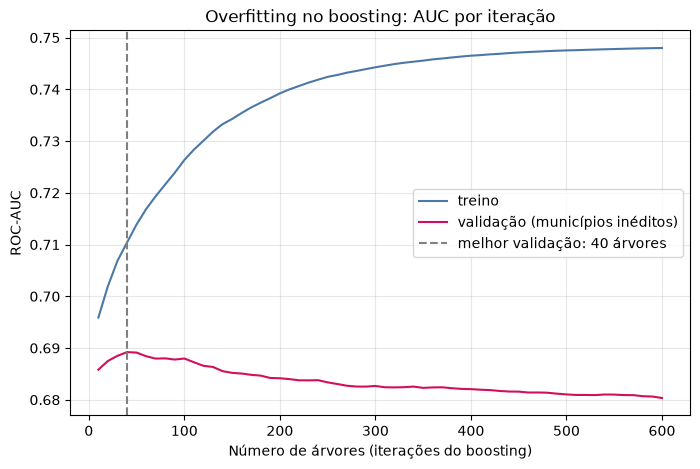

Melhor validação: 0.689 com 40 árvores | no final: treino 0.748 vs validação 0.680


In [3]:
iteracoes, auc_tr, auc_va = curva_por_iteracao(
    dados.decisoes, X_am, y_am, g_am,
    params=dict(learning_rate=0.1, max_depth=6), max_iter=MAX_ITER_CURVA, passo=10)
plot_curva_iteracoes(iteracoes, auc_tr, auc_va, "hgb_curva_iteracoes.png")
melhor = iteracoes[auc_va.argmax()]
print(f"Melhor validação: {auc_va.max():.3f} com {melhor} árvores | "
      f"no final: treino {auc_tr[-1]:.3f} vs validação {auc_va[-1]:.3f}")

**Leitura** (`TODO`: confirmar com o seu gráfico): o AUC de treino sobe sem parar enquanto o de
validação atinge o pico cedo e depois estaciona ou cai: é overfitting. Com taxa de aprendizado
alta e árvores profundas, poucas iterações bastam. O espaço de busca usa taxas menores,
árvores rasas, regularização L2 e no máximo 300 iterações.

## 4. Busca de hiperparâmetros

`RandomizedSearchCV` com `GroupKFold` por município, `refit` em ROC-AUC (como no notebook 04).
Espaço: `learning_rate`, `max_depth`, `max_leaf_nodes`, `min_samples_leaf`,
`l2_regularization` e `max_iter`.

In [4]:
busca = RandomizedSearchCV(
    criar_pipeline(NOME, dados.decisoes), ESPACOS_BUSCA[NOME], n_iter=N_ITER_BUSCA,
    cv=GroupKFold(n_splits=3),
    scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall"},
    refit="roc_auc", n_jobs=1, random_state=RANDOM_STATE, verbose=1,
)
t0 = time.time()
busca.fit(X_am, y_am, groups=g_am)
print(f"Busca concluída em {(time.time() - t0) / 60:.1f} min")

colunas = [c for c in pd.DataFrame(busca.cv_results_).columns if c.startswith("param_modelo__")] + \
          ["mean_test_roc_auc", "mean_test_pr_auc", "mean_test_recall"]
resultados_busca = (pd.DataFrame(busca.cv_results_)[colunas]
                    .sort_values("mean_test_roc_auc", ascending=False).reset_index(drop=True))
resultados_busca.columns = [c.replace("param_modelo__", "").replace("mean_test_", "") for c in colunas]
display(resultados_busca.round(4))

melhores_params = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
print("Melhores hiperparâmetros:", melhores_params)
print(f"ROC-AUC entre {resultados_busca['roc_auc'].min():.3f} e {resultados_busca['roc_auc'].max():.3f}")
PASTA_RELATORIOS.mkdir(parents=True, exist_ok=True)
resultados_busca.to_csv(PASTA_RELATORIOS / "hist_gradient_boosting_busca.csv", index=False, encoding="utf-8-sig")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Busca concluída em 10.3 min


,min_samples_leaf,max_leaf_nodes,max_iter,max_depth,learning_rate,l2_regularization,roc_auc,pr_auc,recall
0,100,15,300,4,0.03,1.0,0.6864,0.5497,0.6514
1,50,31,200,3,0.05,1.0,0.6863,0.5497,0.6559
2,100,15,300,3,0.05,1.0,0.6862,0.5485,0.6503
3,200,15,300,3,0.03,1.0,0.6861,0.5499,0.6562
4,50,15,200,6,0.05,10.0,0.6860,0.5482,0.6398
5,50,31,200,3,0.03,0.0,0.6860,0.5497,0.6619
6,100,31,100,6,0.03,10.0,0.6856,0.5493,0.6541
7,100,31,300,3,0.10,10.0,0.6851,0.5479,0.6409
8,200,15,300,6,0.05,0.0,0.6849,0.5469,0.6370
9,100,31,200,6,0.05,1.0,0.6848,0.5471,0.6405


Melhores hiperparâmetros: {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.03, 'l2_regularization': 1.0}
ROC-AUC entre 0.683 e 0.686


**Leitura** (`TODO`): comparar a amplitude do AUC com a da Random Forest (0,003). Se também for
pequena, reforça a conclusão de que o limite está nos dados e não no algoritmo.

## 5. Limiar de decisão

Mesmo critério do notebook 04: o maior limiar que atinge `META_RECALL`, escolhido com
previsões fora da amostra (o teste não é tocado).

Limiar escolhido: 0.474 (recall 0.700, precisão 0.492)


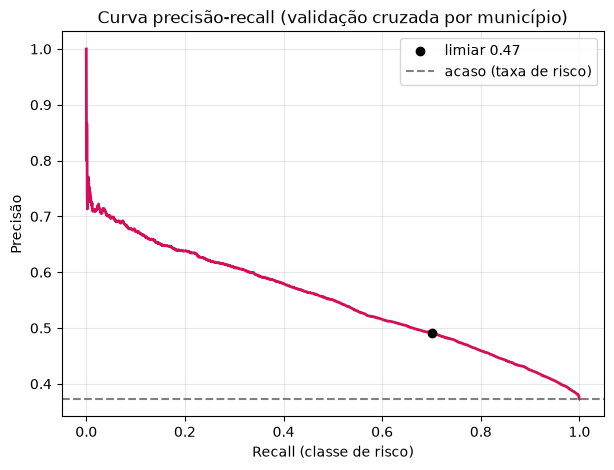

In [5]:
proba_oof = probas_fora_da_amostra(criar_pipeline(NOME, dados.decisoes, **melhores_params),
                                   X_am, y_am, g_am, n_splits=5)
escolha = escolher_limiar(y_am, proba_oof, META_RECALL)
LIMIAR = escolha["limiar"]
print(f"Limiar escolhido: {LIMIAR:.3f} (recall {escolha['recall']:.3f}, precisão {escolha['precisao']:.3f})")
plot_precisao_recall_cv(escolha, y_am.mean(), "hgb_curva_precisao_recall_cv.png")

## 6. Avaliação final no teste (uma única vez)

Treino com todo o treino, hiperparâmetros da busca e o limiar da seção 5.

Treino final: 1,320,423 alunos em 1.3 min


,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos)
limiar 0.50,0.674,0.552,0.624,0.518,0.566,0.474
limiar 0.47 (escolhido),0.674,0.552,0.665,0.509,0.577,0.514


Taxa de risco no teste (precisão do acaso): 39.3%
Em risco: 114,219 | encontradas: 75,927 (66.5%) | não encontradas: 38,292
Alertas: 149,182 | corretos: 50.9% | alarmes falsos: 73,255


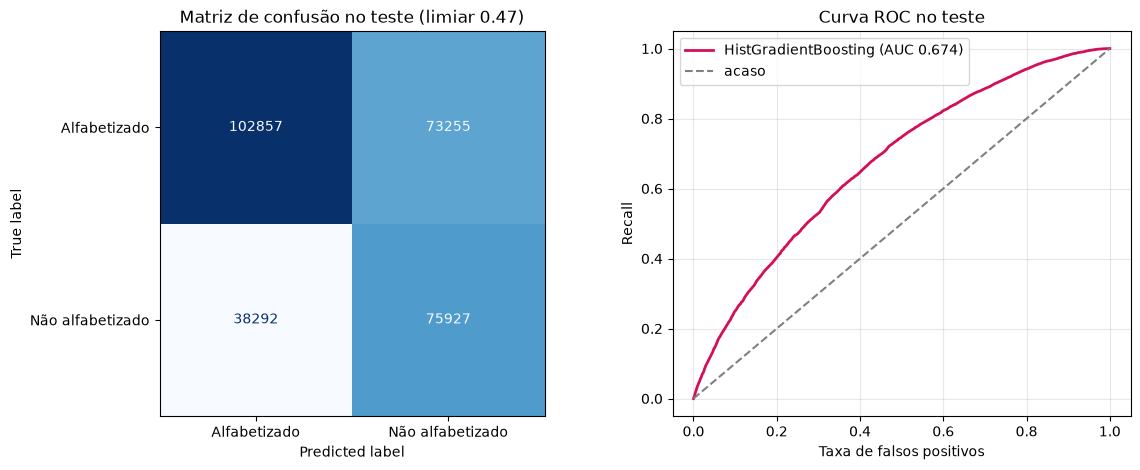

In [6]:
X_fit, y_fit = dados.X_treino, dados.y_treino
t0 = time.time()
modelo_final = criar_pipeline(NOME, dados.decisoes, **melhores_params).fit(X_fit, y_fit)
print(f"Treino final: {len(y_fit):,} alunos em {(time.time() - t0) / 60:.1f} min")

proba_teste, tabela_teste = salvar_resultados(NOME, modelo_final, dados, LIMIAR, META_RECALL,
                                              melhores_params, "HistGradientBoosting")
display(tabela_teste.round(3))

previsto = (proba_teste >= LIMIAR).astype(int)
y_t = dados.y_teste.values
vp = int(((previsto == 1) & (y_t == 1)).sum()); fn = int(((previsto == 0) & (y_t == 1)).sum())
fp = int(((previsto == 1) & (y_t == 0)).sum())
print(f"Taxa de risco no teste (precisão do acaso): {y_t.mean():.1%}")
print(f"Em risco: {vp + fn:,} | encontradas: {vp:,} ({vp / (vp + fn):.1%}) | não encontradas: {fn:,}")
print(f"Alertas: {vp + fp:,} | corretos: {vp / (vp + fp):.1%} | alarmes falsos: {fp:,}")
plot_avaliacao_teste(dados.y_teste, proba_teste, LIMIAR, "HistGradientBoosting", "hgb_avaliacao_teste.png")

## 7. Comparação com os outros modelos no mesmo teste

A regressão logística é treinada aqui com o mesmo critério (se ainda não tiver rodado), e a
Random Forest entra se o notebook 04 já foi executado (ele grava as probabilidades do teste).
Compare principalmente **ROC-AUC e PR-AUC**.

In [7]:
treinar_sem_busca("regressao_logistica", dados, META_RECALL, TETO_ALUNOS)
tabela_comparacao = comparar_teste(dados)
display(tabela_comparacao.round(3))
if "Random Forest" not in tabela_comparacao.index:
    print("Obs.: a Random Forest ainda não aparece; rode o notebook 04 e execute esta célula de novo.")

,roc_auc,pr_auc,recall,precisao,f1,alertas (% dos alunos),limiar
HistGradientBoosting,0.674,0.552,0.665,0.509,0.577,0.514,0.474
Random Forest,0.673,0.549,0.694,0.505,0.585,0.540,0.471
Regressão logística,0.672,0.550,0.687,0.505,0.582,0.535,0.466


**Leitura** (`TODO`): se os modelos empatam dentro do desvio (~0,01 de AUC), a conclusão para o
README é que a **escolha do algoritmo importa pouco** aqui; vale preferir o mais simples e
explicável (regressão logística ou árvore rasa) para a recomendação, e usar o boosting como
verificação de que não há ganho escondido em interações não lineares.

## 8. Importância das features e SHAP

Mesma amostragem por município do notebook 04. **Atenção:** o SHAP do `HistGradientBoosting`
vem em **log-odds**, enquanto o da Random Forest vem em probabilidade. Os valores absolutos não
são comparáveis entre os dois modelos; compare apenas o **ranking** das features.

,queda do ROC-AUC (permutation)
mun_taxa_ano_anterior,0.0795
sigla_uf,0.0416
mun_distancia_meta_anterior,0.0057
regiao,0.0012
mun_total_escolas,0.0011
mun_moradores_por_domicilio,0.0006
mun_populacao,0.0005
mun_pct_integral,0.0004
mun_densidade,0.0004
mun_indice_envelhecimento,0.0003


shape dos valores SHAP: (3270, 52)


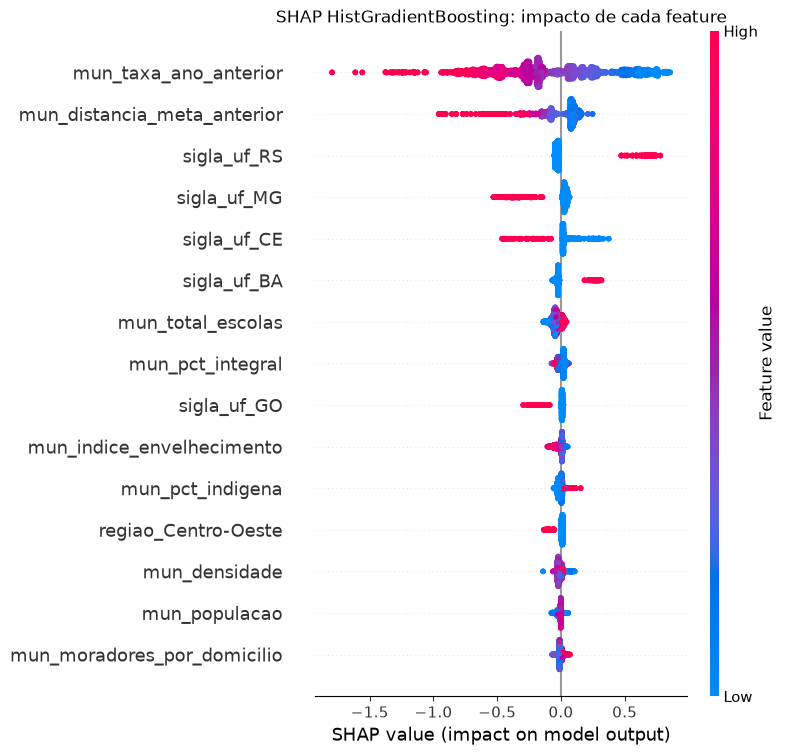

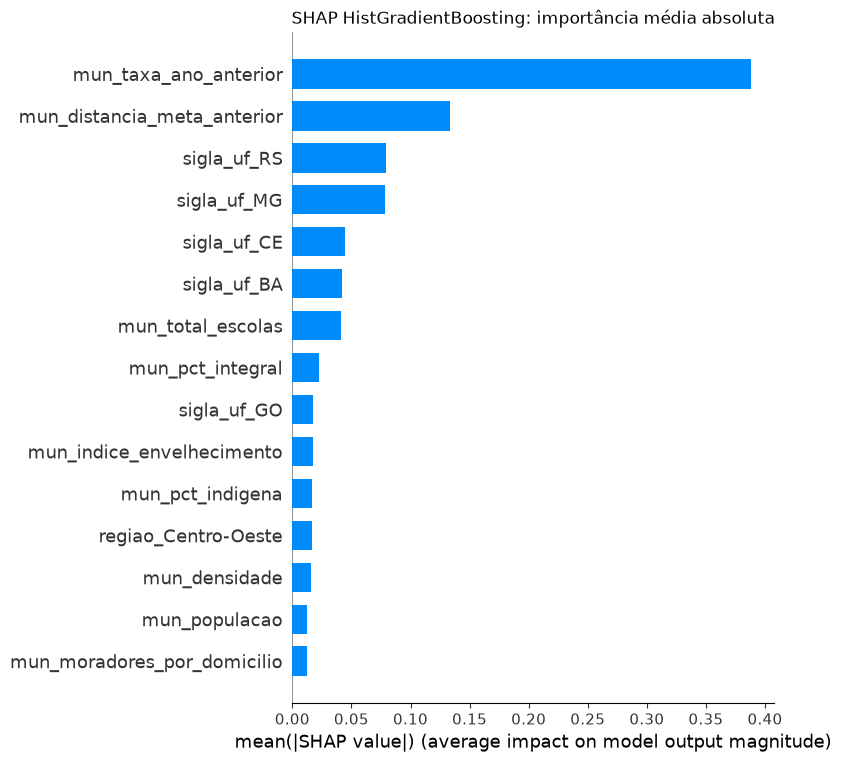

,|SHAP| médio (log-odds)
mun_taxa_ano_anterior,0.3880
mun_distancia_meta_anterior,0.1330
sigla_uf_RS,0.0796
sigla_uf_MG,0.0782
sigla_uf_CE,0.0449
sigla_uf_BA,0.0420
mun_total_escolas,0.0409
mun_pct_integral,0.0224
sigla_uf_GO,0.0174
mun_indice_envelhecimento,0.0171


In [8]:
cols = list(dados.X_treino.columns)
X_perm, y_perm, _ = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_PERMUTACAO)
imp_perm = importancia_permutacao(modelo_final, X_perm[cols], y_perm, n_repeats=5)
display(imp_perm.head(10).round(4).to_frame("queda do ROC-AUC (permutation)"))

X_shap_bruto, _, _ = limitar_por_municipio(dados.X_teste, dados.y_teste, dados.g_teste, TETO_SHAP)
valores, X_shap, nomes_shap = calcular_shap(modelo_final, X_shap_bruto[cols])
print("shape dos valores SHAP:", valores.shape)
plot_shap(valores, X_shap, nomes_shap, "hgb_shap", titulo="HistGradientBoosting")
shap_medio = pd.Series(np.abs(valores).mean(axis=0), index=nomes_shap).sort_values(ascending=False)
display(shap_medio.head(10).round(4).to_frame("|SHAP| médio (log-odds)"))

**Leitura** (`TODO`): comparar o top 5 do SHAP e da permutation com o da Random Forest. Se o
ranking é parecido (esperado: `mun_taxa_ano_anterior` e `mun_distancia_meta_anterior` no topo),
a conclusão sobre os fatores é robusta ao algoritmo. Repetir as ressalvas do notebook 04:
associação não é causa, o RS carrega a anomalia de origem e `mun_pct_rural`/`mun_pct_transporte`
têm valores acima de 100%.

## Síntese

In [9]:
linha = tabela_teste.iloc[1]
print(f"Modelo: HistGradientBoosting {melhores_params}")
print(f"Curva: melhor validação com {melhor} árvores (config agressiva); treino {auc_tr[-1]:.3f} vs validação {auc_va[-1]:.3f} no fim")
print(f"Busca: ROC-AUC entre {resultados_busca['roc_auc'].min():.3f} e {resultados_busca['roc_auc'].max():.3f}")
print(f"Teste (limiar {LIMIAR:.2f}): ROC-AUC {linha['roc_auc']:.3f} | PR-AUC {linha['pr_auc']:.3f} | recall {linha['recall']:.3f} | precisão {linha['precisao']:.3f}")
print("Top 5 SHAP:", ", ".join(shap_medio.head(5).index))
print("Top 5 permutation:", ", ".join(imp_perm.head(5).index))

Modelo: HistGradientBoosting {'min_samples_leaf': 100, 'max_leaf_nodes': 15, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.03, 'l2_regularization': 1.0}
Curva: melhor validação com 40 árvores (config agressiva); treino 0.748 vs validação 0.680 no fim
Busca: ROC-AUC entre 0.683 e 0.686
Teste (limiar 0.47): ROC-AUC 0.674 | PR-AUC 0.552 | recall 0.665 | precisão 0.509
Top 5 SHAP: mun_taxa_ano_anterior, mun_distancia_meta_anterior, sigla_uf_RS, sigla_uf_MG, sigla_uf_CE
Top 5 permutation: mun_taxa_ano_anterior, sigla_uf, mun_distancia_meta_anterior, regiao, mun_total_escolas
